# OliveSmart — OLV-5 : Prévision du rendement des oliveraies

## 1. Problématique

L'objectif de ce projet est de prédire le rendement des oliveraies marocaines avant la récolte, à partir des données historiques, climatiques et satellitaires.

Il s'agit d'un problème de régression supervisée.

- Variables d'entrée (X) : données climatiques, historiques et caractéristiques des parcelles disponibles avant la récolte.
- Variable cible (y) : rendement réel en kilogrammes par hectare (kg/ha).

## 2. Objectif expérimental

Comparer au moins quatre algorithmes, dont une baseline simple, afin de sélectionner le modèle le plus adapté selon ses performances et son coût de calcul.

Modèles envisagés : baseline historique, Ridge, Random Forest, XGBoost, MLP et éventuellement LSTM léger selon la disponibilité des séries temporelles.

## 3. État d'avancement

- Problématique identifiée.
- Modèles de comparaison identifiés.
- Vérification des datasets : en cours.
- Entraînement : non commencé.

In [2]:
# %pip install shapely
import requests
import json
import pandas as pd
import numpy as np
from pathlib import Path
from shapely.geometry import shape, Point
import time
import matplotlib.pyplot as plt

print("OliveSmart OLV-5")
print("Environnement Python prêt")
print("Version Pandas :", pd.__version__)

OliveSmart OLV-5
Environnement Python prêt
Version Pandas : 3.0.3


## 4. Identification des sources de données

Notre projet nécessite plusieurs types de données pour prédire le rendement des oliveraies.

| Source | Données recherchées | État |
|---|---|---|
| FAOSTAT | Production et rendement historique au niveau national | À vérifier |
| NASA POWER | Température, précipitations et climat | À vérifier |
| Sentinel-2 | Indices de végétation | À vérifier |
| FAO WaPOR | Évapotranspiration et données hydriques | À vérifier |
| Collecte Maroc | Rendements réels par parcelle et campagne | À obtenir / constituer |

**Variable cible (y) :** rendement réel en kg/ha.

**Unité d'observation :** une parcelle pendant une campagne agricole.

**Point à clarifier avec le professeur :** disponibilité des données locales de récolte nécessaires à l'entraînement supervisé.

In [2]:
# Dossier actuel de Jupyter
print("Dossier actuel :", Path.cwd())
# Rechercher tous les fichiers CSV
fichiers_csv = list(Path(".").glob("*.csv"))
print("Listes des fichiers CSV trouvés / Notre DataSets :")
for fichier in fichiers_csv:
    print(fichier.name)

Dossier actuel : C:\Users\Ultrapc\Documents\Dev\5_YearEmsi\JEE_DEEPLEARNING_PRJ
Listes des fichiers CSV trouvés / Notre DataSets :
FAOSTAT_data_en_11-2-2026-1y.csv
FAOSTAT_data_en_11-2-2026_3y.csv


### Chargement et affichage des dataset

# FAOSTAT Dataset

In [3]:
# Charger le premier dataset : Yield uniquement
df_FAOSTAT_1y = pd.read_csv("FAOSTAT_data_en_11-2-2026-1y.csv")

# Charger le deuxième dataset : 3 éléments
df_FAOSTAT_3y = pd.read_csv("FAOSTAT_data_en_11-2-2026_3y.csv")

# Afficher les dimensions
print("Yield: Étudier le rendement historique des olives.")
print("Production Quantity: Étudier la quantité totale produite au Maroc.")
print("Area harvested:Étudier l'évolution de la superficie récoltée.\n")

print("DATASET 1 : Yield uniquement")
print("Dimensions :", df_FAOSTAT_1y.shape)
print("Colonnes :", df_FAOSTAT_1y.columns.tolist())
display(df_FAOSTAT_1y.head())

print("\nDATASET 2 : 3 éléments: Yield, Production Quantity, Area harvested")
print("Dimensions :", df_FAOSTAT_3y.shape)
print("Colonnes :", df_FAOSTAT_3y.columns.tolist())
display(df_FAOSTAT_3y.head())

Yield: Étudier le rendement historique des olives.
Production Quantity: Étudier la quantité totale produite au Maroc.
Area harvested:Étudier l'évolution de la superficie récoltée.

DATASET 1 : Yield uniquement
Dimensions : (64, 15)
Colonnes : ['Domain Code', 'Domain', 'Area Code (M49)', 'Area', 'Element Code', 'Element', 'Item Code (CPC)', 'Item', 'Year Code', 'Year', 'Unit', 'Value', 'Flag', 'Flag Description', 'Note']


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Unit,Value,Flag,Flag Description,Note
0,QCL,Crops and livestock products,504,Morocco,5412,Yield,1450,Olives,1961,1961,kg/ha,900.6,E,Estimated value,NaN
1,QCL,Crops and livestock products,504,Morocco,5412,Yield,1450,Olives,1962,1962,kg/ha,906.3,E,Estimated value,NaN
2,QCL,Crops and livestock products,504,Morocco,5412,Yield,1450,Olives,1963,1963,kg/ha,869.6,E,Estimated value,NaN
3,QCL,Crops and livestock products,504,Morocco,5412,Yield,1450,Olives,1964,1964,kg/ha,885.0,E,Estimated value,NaN
4,QCL,Crops and livestock products,504,Morocco,5412,Yield,1450,Olives,1965,1965,kg/ha,890.3,E,Estimated value,NaN



DATASET 2 : 3 éléments: Yield, Production Quantity, Area harvested
Dimensions : (192, 15)
Colonnes : ['Domain Code', 'Domain', 'Area Code (M49)', 'Area', 'Element Code', 'Element', 'Item Code (CPC)', 'Item', 'Year Code', 'Year', 'Unit', 'Value', 'Flag', 'Flag Description', 'Note']


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Unit,Value,Flag,Flag Description,Note
0,QCL,Crops and livestock products,504,Morocco,5312,Area harvested,1450,Olives,1961,1961,ha,155000.0,E,Estimated value,NaN
1,QCL,Crops and livestock products,504,Morocco,5412,Yield,1450,Olives,1961,1961,kg/ha,900.6,E,Estimated value,NaN
2,QCL,Crops and livestock products,504,Morocco,5510,Production,1450,Olives,1961,1961,t,139600.0,A,Official value,NaN
3,QCL,Crops and livestock products,504,Morocco,5312,Area harvested,1450,Olives,1962,1962,ha,160000.0,E,Estimated value,NaN
4,QCL,Crops and livestock products,504,Morocco,5412,Yield,1450,Olives,1962,1962,kg/ha,906.3,E,Estimated value,NaN


In [6]:
# Audit des données FAOSTAT originales

def auditer_dataset(df_FAOSTAT, nom):
    print(f"\n===== AUDIT : {nom} =====")

    print("Dimensions :", df_FAOSTAT.shape)

    print("\nPériode :")
    print(df_FAOSTAT["Year"].min(), "à", df_FAOSTAT["Year"].max())

    print("\nÉléments disponibles :")
    print(df_FAOSTAT["Element"].value_counts())

    print("\nUnités :")
    print(df_FAOSTAT.groupby("Element")["Unit"].unique())

    print("\nValeurs manquantes :")
    print(df_FAOSTAT[["Year", "Element", "Value"]].isna().sum())

    print("\nDoublons (Year + Element) :")
    print(df_FAOSTAT.duplicated(
        subset=["Year", "Element"]
    ).sum())

    print("\nQualité des données :")
    print(df_FAOSTAT["Flag Description"].value_counts(dropna=False))


# Appliquer sur les données brutes
auditer_dataset(df_FAOSTAT_1y, "FAOSTAT 1Y")
auditer_dataset(df_FAOSTAT_3y, "FAOSTAT 3Y")


===== AUDIT : FAOSTAT 1Y =====
Dimensions : (64, 15)

Période :
1961 à 2024

Éléments disponibles :
Element
Yield    64
Name: count, dtype: int64

Unités :
Element
Yield    [kg/ha]
Name: Unit, dtype: object

Valeurs manquantes :
Year       0
Element    0
Value      0
dtype: int64

Doublons (Year + Element) :
0

Qualité des données :
Flag Description
Official value     45
Estimated value    19
Name: count, dtype: int64

===== AUDIT : FAOSTAT 3Y =====
Dimensions : (192, 15)

Période :
1961 à 2024

Éléments disponibles :
Element
Area harvested    64
Yield             64
Production        64
Name: count, dtype: int64

Unités :
Element
Area harvested       [ha]
Production            [t]
Yield             [kg/ha]
Name: Unit, dtype: object

Valeurs manquantes :
Year       0
Element    0
Value      0
dtype: int64

Doublons (Year + Element) :
0

Qualité des données :
Flag Description
Official value                      150
Estimated value                      39
Value from external organizatio

In [8]:
# vérifions que les valeurs Yield sont identiques.

# Rendements du dataset 1
y1 = df_FAOSTAT_1y.set_index("Year")["Value"].sort_index()

# Rendements du dataset 2
y3 = (
    df_FAOSTAT_3y[df_FAOSTAT_3y["Element"] == "Yield"]
    .set_index("Year")["Value"]
    .sort_index()
)

# Comparaison des années et des rendements
memes_annees = y1.index.equals(y3.index)

memes_valeurs = (
    memes_annees
    and np.allclose(y1.values, y3.values)
)

print("Mêmes années :", memes_annees)
print("Mêmes rendements :", memes_valeurs)

Mêmes années : True
Mêmes rendements : True


In [4]:
# Préparer les deux datasets

# Dataset 1 : conserver l'année et le rendement
df_FAOSTAT_yield = df_FAOSTAT_1y[["Year", "Value"]].copy()

df_FAOSTAT_yield = df_FAOSTAT_yield.rename(
    columns={"Value": "Yield"}
)

df_FAOSTAT_yield = df_FAOSTAT_yield.sort_values("Year").reset_index(drop=True)


# Dataset 2 : transformer les éléments en colonnes
df_FAOSTAT_complet = df_FAOSTAT_3y.pivot(
    index="Year",
    columns="Element",
    values="Value"
)

df_FAOSTAT_complet = df_FAOSTAT_complet.reset_index()
df_FAOSTAT_complet.columns.name = None
df_FAOSTAT_complet = df_FAOSTAT_complet.sort_values("Year").reset_index(drop=True)


# Vérifier les deux tableaux
print("DATASET 1 :", df_FAOSTAT_yield.shape)
display(df_FAOSTAT_yield.head())

print("DATASET 2 :", df_FAOSTAT_complet.shape)
display(df_FAOSTAT_complet.head())

DATASET 1 : (64, 2)


,Year,Yield
0,1961,900.6
1,1962,906.3
2,1963,869.6
3,1964,885.0
4,1965,890.3


DATASET 2 : (64, 4)


,Year,Area harvested,Production,Yield
0,1961,155000.0,139600.0,900.6
1,1962,160000.0,145000.0,906.3
2,1963,230000.0,200000.0,869.6
3,1964,200000.0,177000.0,885.0
4,1965,300000.0,267100.0,890.3


## Conclusion de l'audit FAOSTAT

Les données FAOSTAT concernant les olives au Maroc couvrent la période 1961–2024.

Deux configurations ont été extraites :
- FAOSTAT 1Y : rendement agricole annuel.
- FAOSTAT 3Y : rendement, production et superficie récoltée.
L'analyse des colonnes essentielles n'a révélé aucune valeur manquante ni aucun doublon par année et élément.

Les rendements sont exprimés en kg/ha. Les données comprennent des valeurs officielles et estimées, dont les statuts sont conservés.

Les deux configurations serviront à étudier l'influence des variables historiques sur la qualité des prédictions. Les données concernent toutefois l'échelle nationale et non des parcelles individuelles.

# NASA POWER DataSet

In [9]:
# Trouver les fichiers NASA téléchargés
fichiers_nasa = list(
    Path(".").glob("POWER_Regional_Monthly*.csv")
)

print("Fichiers NASA trouvés :")
for f in fichiers_nasa:
    print(f.name)

# Lire le premier fichier
if fichiers_nasa:
    df_nasa = pd.read_csv(
        fichiers_nasa[0],
        skiprows=9,
        na_values=[-999]
    )

    print("\nDimensions :", df_nasa.shape)
    print("\nColonnes :", df_nasa.columns.tolist())

    display(df_nasa.head())
else:
    print("Aucun fichier NASA trouvé.")

Fichiers NASA trouvés :
POWER_Regional_Monthly_1984_2024.csv

Dimensions : (820, 17)

Colonnes : ['PARAMETER', 'YEAR', 'LAT', 'LON', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANN']


,PARAMETER,YEAR,LAT,LON,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANN
0,T2M,1984,33.0,-4.375,4.36,5.75,7.74,13.86,11.68,21.27,26.66,25.01,21.12,14.22,9.37,5.14,13.86
1,T2M,1984,33.0,-5.000,3.29,4.48,6.11,11.92,9.31,18.83,24.58,22.95,19.16,13.07,7.79,4.47,12.18
2,T2M,1984,33.0,-5.625,5.72,7.13,8.70,14.17,11.16,20.65,27.32,25.40,21.87,16.01,10.16,7.38,14.66
3,T2M,1984,33.0,-6.250,8.33,10.00,11.81,17.11,13.94,22.74,30.08,27.55,24.52,19.00,13.13,10.44,17.41
4,T2M,1984,33.5,-4.375,3.60,4.55,6.62,12.17,9.70,18.94,25.29,23.50,19.68,12.83,8.52,4.77,12.53


In [10]:
# ÉTAPE 3.9 : Audit du dataset NASA POWER

def auditer_nasa(df):
    print("===== AUDIT NASA POWER =====")

    print("\n1. Dimensions :", df.shape)

    print("\n2. Période :")
    print(df["YEAR"].min(), "à", df["YEAR"].max())

    print("\n3. Paramètres disponibles :")
    print(df["PARAMETER"].value_counts())

    print("\n4. Nombre de points géographiques :")
    points = df[["LAT", "LON"]].drop_duplicates()
    print(len(points))

    print("\n5. Observations par année :")
    print(df.groupby("YEAR").size().value_counts())

    print("\n6. Valeurs manquantes :")
    print(df.isna().sum())

    print("\n7. Doublons :")
    print(df.duplicated(
        subset=["PARAMETER", "YEAR", "LAT", "LON"]
    ).sum())

    print("\n8. Statistiques des températures annuelles :")
    print(df["ANN"].describe())


auditer_nasa(df_nasa)

===== AUDIT NASA POWER =====

1. Dimensions : (820, 17)

2. Période :
1984 à 2024

3. Paramètres disponibles :
PARAMETER
T2M    820
Name: count, dtype: int64

4. Nombre de points géographiques :
20

5. Observations par année :
20    41
Name: count, dtype: int64

6. Valeurs manquantes :
PARAMETER    0
YEAR         0
LAT          0
LON          0
JAN          0
FEB          0
MAR          0
APR          0
MAY          0
JUN          0
JUL          0
AUG          0
SEP          0
OCT          0
NOV          0
DEC          0
ANN          0
dtype: int64

7. Doublons :
0

8. Statistiques des températures annuelles :
count    820.000000
mean      17.050390
std        2.175253
min       11.420000
25%       15.490000
50%       17.415000
75%       18.862500
max       21.510000
Name: ANN, dtype: float64


In [13]:
# Un point géographique de notre fichier NASA
latitude = float(df_nasa.iloc[0]["LAT"])
longitude = float(df_nasa.iloc[0]["LON"])

# Les six variables climatiques souhaitées
parametres = [
    "T2M",
    "T2M_MAX",
    "T2M_MIN",
    "PRECTOTCORR",
    "RH2M",
    "ALLSKY_SFC_SW_DWN"
]

url = "https://power.larc.nasa.gov/api/temporal/monthly/point"

options = {
    "parameters": ",".join(parametres),
    "community": "AG",
    "latitude": latitude,
    "longitude": longitude,
    "start": 1984,
    "end": 2024,
    "format": "JSON"
}

print("Point testé :", latitude, longitude)

reponse = requests.get(url, params=options, timeout=60)

print("Code HTTP :", reponse.status_code)

if reponse.ok:
    donnees = reponse.json()

    variables_recues = donnees["properties"]["parameter"]

    print("Paramètres reçus :")
    print(list(variables_recues.keys()))

    for nom, valeurs in variables_recues.items():
        print(nom, ":", len(valeurs), "valeurs")
else:
    print("Erreur de l'API :")
    print(reponse.text[:1000])

Point testé : 33.0 -4.375
Code HTTP : 200
Paramètres reçus :
['ALLSKY_SFC_SW_DWN', 'PRECTOTCORR', 'RH2M', 'T2M', 'T2M_MAX', 'T2M_MIN']
ALLSKY_SFC_SW_DWN : 533 valeurs
PRECTOTCORR : 533 valeurs
RH2M : 533 valeurs
T2M : 533 valeurs
T2M_MAX : 533 valeurs
T2M_MIN : 533 valeurs


In [21]:
# Charger les frontières du Maroc
chemin = Path("maroc.geojson")

if not chemin.exists():
    raise FileNotFoundError(
        "Il faut d'abord placer maroc.geojson dans le dossier."
    )

with open(chemin, "r", encoding="utf-8") as f:
    geojson = json.load(f)

# Accepter un GeoJSON contenant un seul territoire
if geojson["type"] == "FeatureCollection":
    assert len(geojson["features"]) == 1
    geom = shape(geojson["features"][0]["geometry"])
elif geojson["type"] == "Feature":
    geom = shape(geojson["geometry"])
else:
    geom = shape(geojson)

# Limites géographiques
lon_min, lat_min, lon_max, lat_max = geom.bounds

# Grille d'environ 1 degré
points = []

for lat in np.arange(lat_min + 0.5, lat_max, 1.0):
    for lon in np.arange(lon_min + 0.5, lon_max, 1.0):

        if geom.covers(Point(float(lon), float(lat))):
            points.append((round(float(lat), 3),
                           round(float(lon), 3)))

print("Nombre de points au Maroc :", len(points))
print("Exemples :", points[:5])

print("Type de géométrie :", geom.geom_type)
print("Géométrie valide :", geom.is_valid)

print("\nLimites géographiques :")
print("Longitude min :", lon_min)
print("Latitude min :", lat_min)
print("Longitude max :", lon_max)
print("Latitude max :", lat_max)

print("\nNombre de points générés :", len(points))

Nombre de points au Maroc : 58
Exemples : [(22.27, -16.605), (22.27, -15.605), (22.27, -14.605), (22.27, -13.605), (23.27, -15.605)]
Type de géométrie : Polygon
Géométrie valide : True

Limites géographiques :
Longitude min : -17.104826199999973
Latitude min : 20.769782599999957
Longitude max : -0.998429
Latitude max : 35.922427099999965

Nombre de points générés : 58


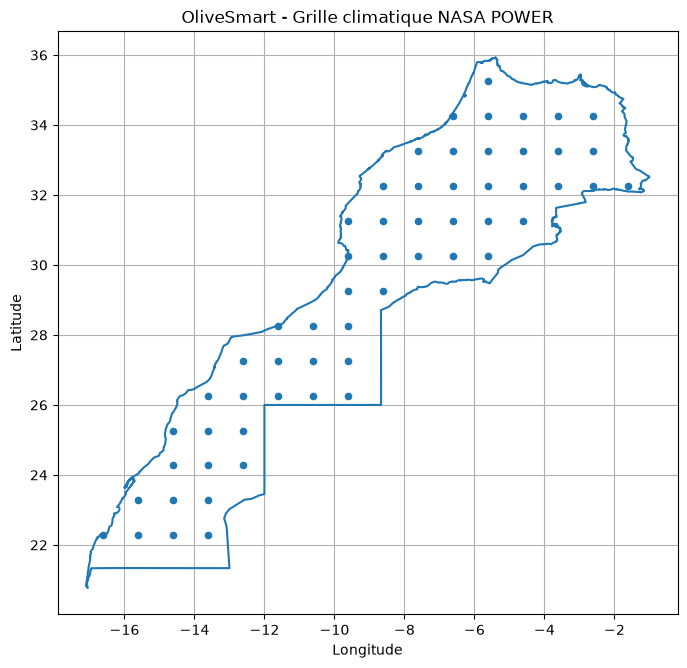

In [25]:
# Créer la figure
fig, ax = plt.subplots(figsize=(8, 9))

# Afficher les frontières du GeoJSON
x, y = geom.exterior.xy
ax.plot(x, y)

# Afficher les points NASA de notre grille
latitudes = [lat for lat, lon in points]
longitudes = [lon for lat, lon in points]

ax.scatter(longitudes, latitudes, s=20)

ax.set_title("OliveSmart - Grille climatique NASA POWER")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
ax.grid(True)

plt.show()

In [22]:
PARAMETRES = [
    "T2M", "T2M_MAX", "T2M_MIN",
    "PRECTOTCORR", "RH2M", "ALLSKY_SFC_SW_DWN"
]

CACHE = Path("cache_nasa")
CACHE.mkdir(exist_ok=True)

def recuperer_point(lat, lon):
    cache_file = CACHE / f"{lat}_{lon}.json"

    if cache_file.exists():
        return json.loads(cache_file.read_text())

    url = "https://power.larc.nasa.gov/api/temporal/monthly/point"

    params = {
        "parameters": ",".join(PARAMETRES),
        "community": "AG",
        "latitude": lat,
        "longitude": lon,
        "start": 1984,
        "end": 2024,
        "format": "JSON"
    }

    for tentative in range(4):
        try:
            r = requests.get(url, params=params, timeout=90)
            r.raise_for_status()
            data = r.json()

            cache_file.write_text(json.dumps(data))
            return data

        except (requests.RequestException, ValueError):
            if tentative == 3:
                raise
            time.sleep(2 ** tentative)


def construire_dataset_nasa(points):
    lignes = []

    for i, (lat, lon) in enumerate(points, 1):
        print(f"Point {i}/{len(points)} : {lat}, {lon}")

        data = recuperer_point(lat, lon)
        variables = data["properties"]["parameter"]

        for annee in range(1984, 2025):
            for mois in range(1, 13):

                cle = f"{annee}{mois:02d}"

                ligne = {
                    "YEAR": annee,
                    "MONTH": mois,
                    "LAT": lat,
                    "LON": lon
                }

                for variable in PARAMETRES:
                    valeur = variables.get(variable, {}).get(cle)

                    ligne[variable] = (
                        np.nan
                        if valeur is None or float(valeur) <= -999
                        else float(valeur)
                    )

                lignes.append(ligne)

    return pd.DataFrame(lignes)


# Test : seulement 2 points pour commencer
df_test = construire_dataset_nasa(points[:2])

display(df_test.head())

Point 1/2 : 22.27, -16.605
Point 2/2 : 22.27, -15.605


,YEAR,MONTH,LAT,LON,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,ALLSKY_SFC_SW_DWN
0,1984,1,22.27,-16.605,17.68,22.29,13.95,0.03,72.14,15.24
1,1984,2,22.27,-16.605,17.62,24.23,14.17,0.01,73.36,18.85
2,1984,3,22.27,-16.605,18.24,28.56,15.71,0.02,77.08,22.97
3,1984,4,22.27,-16.605,19.21,24.19,17.05,0.00,82.83,25.14
4,1984,5,22.27,-16.605,18.86,20.91,16.99,0.05,82.78,24.65


In [23]:
# Construction du Nasa Power DataSet
df_nasa_maroc = construire_dataset_nasa(points)

df_nasa_maroc.to_csv(
    "NASA_POWER_Maroc_1984_2024.csv",
    index=False
)

Point 1/58 : 22.27, -16.605
Point 2/58 : 22.27, -15.605
Point 3/58 : 22.27, -14.605
Point 4/58 : 22.27, -13.605
Point 5/58 : 23.27, -15.605
Point 6/58 : 23.27, -14.605
Point 7/58 : 23.27, -13.605
Point 8/58 : 24.27, -14.605
Point 9/58 : 24.27, -13.605
Point 10/58 : 24.27, -12.605
Point 11/58 : 25.27, -14.605
Point 12/58 : 25.27, -13.605
Point 13/58 : 25.27, -12.605
Point 14/58 : 26.27, -13.605
Point 15/58 : 26.27, -12.605
Point 16/58 : 26.27, -11.605
Point 17/58 : 26.27, -10.605
Point 18/58 : 26.27, -9.605
Point 19/58 : 27.27, -12.605
Point 20/58 : 27.27, -11.605
Point 21/58 : 27.27, -10.605
Point 22/58 : 27.27, -9.605
Point 23/58 : 28.27, -11.605
Point 24/58 : 28.27, -10.605
Point 25/58 : 28.27, -9.605
Point 26/58 : 29.27, -9.605
Point 27/58 : 29.27, -8.605
Point 28/58 : 30.27, -9.605
Point 29/58 : 30.27, -8.605
Point 30/58 : 30.27, -7.605
Point 31/58 : 30.27, -6.605
Point 32/58 : 30.27, -5.605
Point 33/58 : 31.27, -9.605
Point 34/58 : 31.27, -8.605
Point 35/58 : 31.27, -7.605
Point 3

In [26]:
# Charger le dataset NASA national
df_nasa_maroc = pd.read_csv(
    "NASA_POWER_Maroc_1984_2024.csv"
)

print("===== AUDIT FINAL NASA POWER =====")

print("Dimensions :", df_nasa_maroc.shape)

print("Période :",
      df_nasa_maroc["YEAR"].min(),
      "à",
      df_nasa_maroc["YEAR"].max())

print("Points géographiques :",
      df_nasa_maroc[["LAT", "LON"]]
      .drop_duplicates().shape[0])

print("Mois disponibles :",
      sorted(df_nasa_maroc["MONTH"].unique()))

print("Valeurs manquantes :")
print(df_nasa_maroc.isna().sum())

print("Doublons :",
      df_nasa_maroc.duplicated(
          subset=["YEAR", "MONTH", "LAT", "LON"]
      ).sum())

print("Colonne rendement présente :",
      "rendement_kg_ha" in df_nasa_maroc.columns)

print("Nombre de lignes attendu :", 58 * 41 * 12)
print("Nombre de lignes obtenu :", len(df_nasa_maroc))

===== AUDIT FINAL NASA POWER =====
Dimensions : (28536, 10)
Période : 1984 à 2024
Points géographiques : 58
Mois disponibles : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
Valeurs manquantes :
YEAR                 0
MONTH                0
LAT                  0
LON                  0
T2M                  0
T2M_MAX              0
T2M_MIN              0
PRECTOTCORR          0
RH2M                 0
ALLSKY_SFC_SW_DWN    0
dtype: int64
Doublons : 0
Colonne rendement présente : False
Nombre de lignes attendu : 28536
Nombre de lignes obtenu : 28536


# Sentinel-2 (Earth Engine) DataSet

In [3]:
# Charger Sentinel-2
df_sentinel = pd.read_csv(
    "OLV5_Sentinel2_NDVI_2019_2024.csv"
)
# NDVI (Normalized Difference Vegetation Index)

# Convertir les années et mois en entiers
df_sentinel["Year"] = df_sentinel["Year"].astype(int)
df_sentinel["Month"] = df_sentinel["Month"].astype(int)

# AUDIT
print("===== AUDIT SENTINEL-2 =====")

print("Dimensions :", df_sentinel.shape)

print("Années :",
      df_sentinel["Year"].min(),
      "à",
      df_sentinel["Year"].max())

print("\nValeurs manquantes :")
print(df_sentinel.isna().sum())

print("\nDoublons :")
print(df_sentinel.duplicated(
    subset=["Year", "Month"]
).sum())

print("\nStatistiques NDVI :")
print(df_sentinel["NDVI_mean"].describe())

print("\nImages par mois :")
print(df_sentinel["Image_count"].describe())

# Vérifier que les 72 mois sont présents
print("\nNombre de mois :", len(df_sentinel))

# Vérifications de cohérence
assert len(df_sentinel) == 72
assert df_sentinel[["Year", "Month"]].duplicated().sum() == 0
assert df_sentinel["Month"].between(1, 12).all()
assert df_sentinel["NDVI_mean"].between(-1, 1).all()

# Enregistrer une copie auditée
df_sentinel.to_csv(
    "Sentinel2_FesMeknes_2019_2024_AUDITED.csv",
    index=False
)

display(df_sentinel.head())

===== AUDIT SENTINEL-2 =====
Dimensions : (72, 4)
Années : 2019 à 2024

Valeurs manquantes :
Year           0
Month          0
NDVI_mean      0
Image_count    0
dtype: int64

Doublons :
0

Statistiques NDVI :
count    72.000000
mean      0.306316
std       0.088421
min       0.200003
25%       0.225747
50%       0.285461
75%       0.381753
max       0.483375
Name: NDVI_mean, dtype: float64

Images par mois :
count     72.000000
mean     147.013889
std       23.437356
min       92.000000
25%      132.500000
50%      144.500000
75%      162.000000
max      197.000000
Name: Image_count, dtype: float64

Nombre de mois : 72


,Year,Month,NDVI_mean,Image_count
0,2019,1,0.453139,155
1,2019,2,0.483375,142
2,2019,3,0.442396,135
3,2019,4,0.397900,125
4,2019,5,0.328400,146


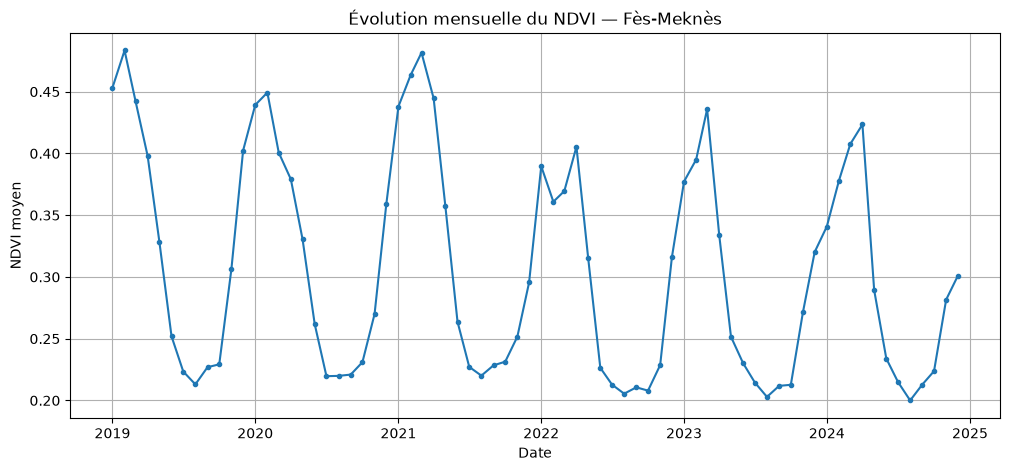

In [4]:
df_sentinel["Date"] = pd.to_datetime(
    dict(
        year=df_sentinel["Year"],
        month=df_sentinel["Month"],
        day=1
    )
)

plt.figure(figsize=(12, 5))

plt.plot(
    df_sentinel["Date"],
    df_sentinel["NDVI_mean"],
    marker="o",
    markersize=3
)

plt.title("Évolution mensuelle du NDVI — Fès-Meknès")
plt.xlabel("Date")
plt.ylabel("NDVI moyen")
plt.grid(True)
plt.show()

# FAO WaPOR DataSet